# 08 · Distillation: Post-Training a Diffusion Model to Sample in a Few Steps

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Pretraining | Next-token prediction on raw text | Knowledge: the model *can* add | Doesn't follow instructions |
| 02 | SFT + LoRA | Imitate demonstrations | Follows the chat format | Copies demonstrators' mistakes; forgets |
| 03 | Reward model + PPO | Learn a reward from preferences, optimise it | Can go beyond imitation | Reward hacking; four models; fragile |
| 04 | DPO family | Optimise preferences directly, no RL loop | Simple and stable | Offline: only re-weights existing behaviour |
| 05 | GRPO / RLVR | Online RL against a verifier | Verifiable gains, no value network | Sharpens, rarely expands; needs a capable start |
| 06 | Diffusion | Learn to denoise | Stable, high-quality generation | Matches data, not *goals*; slow sampling |
| 07 | Diffusion post-training | Fine-tune and reward-align a denoiser | Steer generation to a goal | Reward hacking again; still slow |
| **08** | **Distillation** | **Few-step students** | **10-100x faster sampling** | **Small denoisers don't scale** |
| 09 | Diffusion transformers | Tokens + adaLN + flow matching | Scalable, flexible conditioning | Needs post-training too |
| 10 | Capstone | GRPO and DPO on a DiT; diffusion LMs | Unifies both threads | → the research frontier |

Notebook 06 measured the price of diffusion: good samples needed tens of network evaluations (NFE), where a
GAN needs one. In production, that price is paid on every image, so a large part of diffusion post-training is
**distillation**: training a *student* that reproduces a *teacher's* sampler in far fewer steps. Three families,
each with a different idea of what to match:

* **Progressive distillation** ([Salimans & Ho, 2022](https://arxiv.org/abs/2202.00512)): match *two* teacher steps with one, then repeat, halving the steps each round.
* **Consistency distillation** ([Song et al., 2023](https://arxiv.org/abs/2303.01469)): learn a function that maps *every* point on a teacher trajectory to the same endpoint.
* **Rectified flow and reflow** ([Liu et al., 2022](https://arxiv.org/abs/2209.03003)): make the trajectories themselves *straight*, so a single Euler step is accurate.

Later systems combine these ideas with adversarial or distribution-matching losses: LCM ([Luo et al., 2023](https://arxiv.org/abs/2310.04378)), ADD
([Sauer et al., 2023](https://arxiv.org/abs/2311.17042)) and DMD ([Yin et al., 2023](https://arxiv.org/abs/2311.18828)) are among the one-to-four-step generators used in practice.

## Learning objectives

1. Explain why few-step deterministic sampling fails: curved trajectories and blurry early predictions of $x_0$.
2. Implement progressive and consistency distillation from notebook 06's teacher.
3. Train a rectified flow, apply one round of reflow, and compare all methods on quality vs NFE.
4. Test whether the alignment from notebook 07 survives distillation.

**Runtime:** about 8 minutes on a laptop CPU.

In [1]:
import sys, time, copy, os, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
sys.path.insert(0, ".")
from ptlib import images, metrics, set_seed, CKPT_DIR
from ptlib import diffusion as dfx
torch.set_num_threads(min(8, torch.get_num_threads()))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
Xtr, ytr, Xte, yte = images.load_digits_tensor()
teacher = dfx.get_base_diffusion()
judge = images.get_judge()
sc = metrics.ImageScorecard(judge, Xtr, Xte, yte)
real = sc.real_baseline()
print("real-data floor: FD", round(real["fd"], 2))
results = []           # (method, nfe, fd, precision, coverage, judge_acc)
def score(samples, method, nfe):
    r = sc.evaluate(samples, f"{method}, {nfe} step{'s' if nfe > 1 else ''}", labels=yte, nfe=nfe)
    results.append(dict(method=method, nfe=nfe, **{k: r[k] for k in ["fd", "precision", "coverage", "judge_acc"]}))
    return r

real-data floor: FD 3.32


## 1. Why few-step sampling fails

Deterministic DDIM integrates an ODE from noise to data. Each step uses the network's current estimate $\hat x_0$
and moves along a straight line toward it. At high noise, $\hat x_0$ is the **average** of every image consistent
with $x_t$: a blur. The true trajectory bends as that average sharpens, and one big step lands on the blur.

,method,nfe,fd,precision,coverage,judge_acc
0,teacher (DDIM),1,90.883,0.393,0.050,1.000
1,teacher (DDIM),2,28.684,0.905,0.682,1.000
2,teacher (DDIM),4,12.304,0.975,0.933,0.992
3,teacher (DDIM),8,7.762,0.981,0.944,0.992
4,teacher (DDIM),16,6.412,0.983,0.953,0.989
5,teacher (DDIM),64,5.978,0.981,0.955,0.989


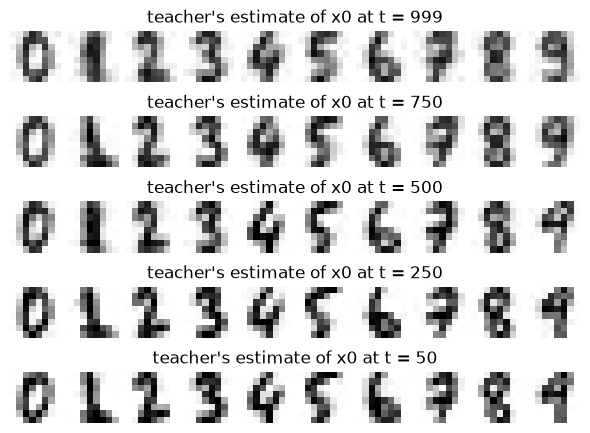

In [2]:
for N in [1, 2, 4, 8, 16, 64]:
    set_seed(0); score(dfx.sample_grid(teacher, yte, N), "teacher (DDIM)", N)
display(pd.DataFrame(results).round(3))
set_seed(0)
x = torch.randn(10, 64); lab = torch.arange(10)
with torch.no_grad():
    rows = []
    for t in [999, 750, 500, 250, 50]:
        tt = torch.full((10,), t)
        x_t = dfx.q_sample(dfx.sample_grid(teacher, lab, 64, x_T=x), tt, torch.randn(10, 64)) if t < 999 else x
        rows.append(dfx.to_x0_eps(teacher(x_t, tt, lab), x_t, tt)[0].clamp(-1, 1))
fig, axes = plt.subplots(5, 1, figsize=(6, 4.5))
for ax, t, r in zip(axes, [999, 750, 500, 250, 50], rows):
    images.show_grid(r, nrow=10, ax=ax, title=f"teacher's estimate of x0 at t = {t}")
fig.tight_layout(); plt.show()

## 2. Progressive distillation

Start with the teacher's $N$-step sampler. Train a student, initialised as a copy of the teacher, so that **one**
student step from $t$ to $t''$ lands exactly where **two** teacher steps ($t \to t' \to t''$) land. Given the teacher's endpoint
$x_{t''}$, the clean-image target that makes a single DDIM step hit it is available in closed form:
$$\tilde x_0 = \frac{x_{t''} - (\sigma_{t''}/\sigma_t)\,x_t}{\alpha_{t''} - (\sigma_{t''}/\sigma_t)\,\alpha_t}, \qquad \alpha = \sqrt{\bar\alpha},\; \sigma = \sqrt{1-\bar\alpha}.$$
The student regresses onto it (in $v$-space). Then the student becomes the teacher, and $N$ halves again: 64 → 32 → … → 1.

In [3]:
t0 = time.time()
students = dfx.progressive_distillation(teacher, Xtr, ytr, start=64, end=1, iters_per_round=600)
t_pd = time.time() - t0
for N in [1, 2, 4, 8]:
    set_seed(0); score(dfx.sample_grid(students[N], yte, N), "progressive distillation", N)
display(pd.DataFrame(results).query("method == 'progressive distillation'").round(3))

distilled 64 -> 32 steps  (loss 0.0046, 17s)
distilled 32 -> 16 steps  (loss 0.0028, 33s)
distilled 16 -> 8 steps  (loss 0.0013, 49s)
distilled 8 -> 4 steps  (loss 0.0015, 66s)
distilled 4 -> 2 steps  (loss 0.0025, 82s)
distilled 2 -> 1 steps  (loss 0.0068, 99s)


,method,nfe,fd,precision,coverage,judge_acc
6,progressive distillation,1,24.576,0.922,0.791,0.975
7,progressive distillation,2,18.769,0.953,0.858,0.978
8,progressive distillation,4,14.021,0.969,0.894,0.978
9,progressive distillation,8,11.940,0.975,0.916,0.983


## 3. Consistency distillation

A **consistency function** $f_\theta(x_t, t)$ maps any point on an ODE trajectory to the trajectory's origin $x_0$. Its defining
property is self-consistency: adjacent points must map to the same output. Consistency distillation ([Song et al., 2023](https://arxiv.org/abs/2303.01469))
enforces it with one teacher ODE step:
$$\mathcal{L} = \big\| f_\theta(x_{t_{n+1}}, t_{n+1}) - f_{\theta^-}(\hat x_{t_n}, t_n) \big\|^2,\qquad \hat x_{t_n} = \text{DDIM}_\text{teacher}(x_{t_{n+1}} \to t_n),$$
with $\theta^-$ an exponential moving average of $\theta$. At $t = 0$, $f$ is the identity, and that boundary condition is
what propagates correct answers up the trajectory. Sampling takes one step, $f(x_T, T)$. For more steps, re-noise the
output to an intermediate time and apply $f$ again.

In [4]:
t0 = time.time()
cm = dfx.consistency_distillation(teacher, Xtr, ytr, N=32, iters=3000)
t_cd = time.time() - t0
for n in [1, 2, 4]:
    set_seed(0); score(dfx.sample_consistency(cm, yte, n), "consistency distillation", n)
display(pd.DataFrame(results).query("method == 'consistency distillation'").round(3))

consistency step 1000: loss 0.00035
consistency step 2000: loss 0.00028
consistency step 3000: loss 0.00033


,method,nfe,fd,precision,coverage,judge_acc
10,consistency distillation,1,57.531,0.708,0.460,0.961
11,consistency distillation,2,35.310,0.838,0.708,0.983
12,consistency distillation,4,21.442,0.939,0.819,0.989


## 4. Rectified flow and reflow

**Rectified flow** ([Liu et al., 2022](https://arxiv.org/abs/2209.03003)), and the closely related **flow matching** ([Lipman et al., 2022](https://arxiv.org/abs/2210.02747)), skip the noise schedule
altogether: interpolate in a straight line between data $x$ and noise $z$, $x_s = (1-s)\,x + s\,z$ for $s \in [0,1]$, and regress the
velocity $u = z - x$. Sampling integrates $dx/ds = u_\theta$ backwards with Euler steps. This is the objective behind
Stable Diffusion 3 and FLUX (notebook 09).

Each *training pair* travels in a straight line, but the learned flow need not: many $(x, z)$ pairs cross, and the
network learns their average direction, which curves. **Reflow** is the post-training step. Generate pairs
$(z, \hat x)$ by running the trained flow from $z$, then train a new flow on these *coupled* pairs. The paths no longer cross, so
the new flow is straighter, and a single Euler step becomes accurate.

In [5]:
t0 = time.time()
rf1, _ = dfx.train_flow(dfx.MLPDenoiser(), Xtr, ytr, steps=6000, log_every=0)
t_rf1 = time.time() - t0
for n in [1, 2, 4, 8, 20]:
    set_seed(0); score(dfx.sample_flow(rf1, yte, n), "rectified flow (1-RF)", n)

t0 = time.time()
set_seed(5)
y_pairs = torch.randint(0, 10, (10000,)); z = torch.randn(10000, 64)
x_hat = dfx.sample_flow(rf1, y_pairs, 50, x_T=z).clamp(-1, 1)                 # couple each noise with its sample
rf2, _ = dfx.train_flow(copy.deepcopy(rf1), x_hat, y_pairs, X0=z, steps=3000, lr=3e-4, p_uncond=0.0, log_every=0)
t_rf2 = time.time() - t0
for n in [1, 2, 4, 8, 20]:
    set_seed(0); score(dfx.sample_flow(rf2, yte, n), "reflow (2-RF)", n)

@torch.no_grad()
def straightness(model, n=500, steps=50):
    # mean squared deviation of the velocity along a trajectory from the straight line (z - x_end); 0 = perfectly straight
    set_seed(0); lab = torch.randint(0, 10, (n,))
    x_end, traj = dfx.sample_flow(model, lab, steps, return_traj=True)
    chord = traj[0] - x_end
    vel = [(traj[i] - traj[i + 1]) * steps for i in range(steps)]
    return float(torch.stack([((v - chord) ** 2).mean() for v in vel]).mean())
print(f"straightness (lower = straighter): 1-RF {straightness(rf1):.4f}   2-RF {straightness(rf2):.4f}")

straightness (lower = straighter): 1-RF 0.0791   2-RF 0.0123


## 5. All methods: quality vs cost

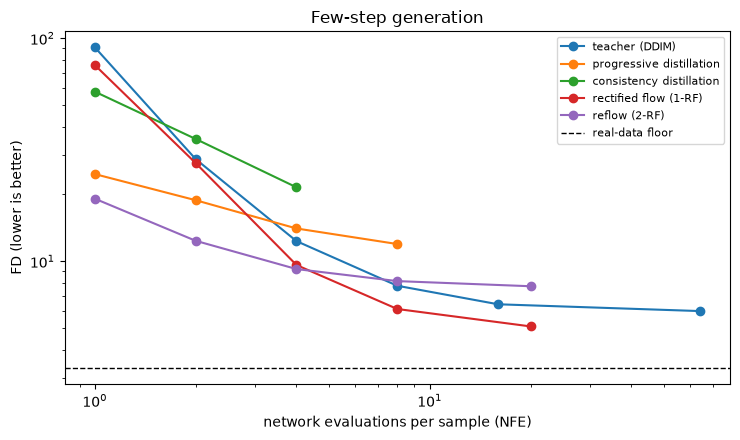

nfe,1,2,4,8,16,64,20
method,,,,,,,
teacher (DDIM),90.88,28.68,12.30,7.76,6.41,5.98,NaN
progressive distillation,24.58,18.77,14.02,11.94,NaN,NaN,NaN
consistency distillation,57.53,35.31,21.44,NaN,NaN,NaN,NaN
rectified flow (1-RF),75.67,27.53,9.62,6.11,NaN,NaN,5.10
reflow (2-RF),19.06,12.35,9.22,8.14,NaN,NaN,7.72


training cost: progressive 99s | consistency 81s | rectified flow 113s | reflow (incl. pair generation) 61s


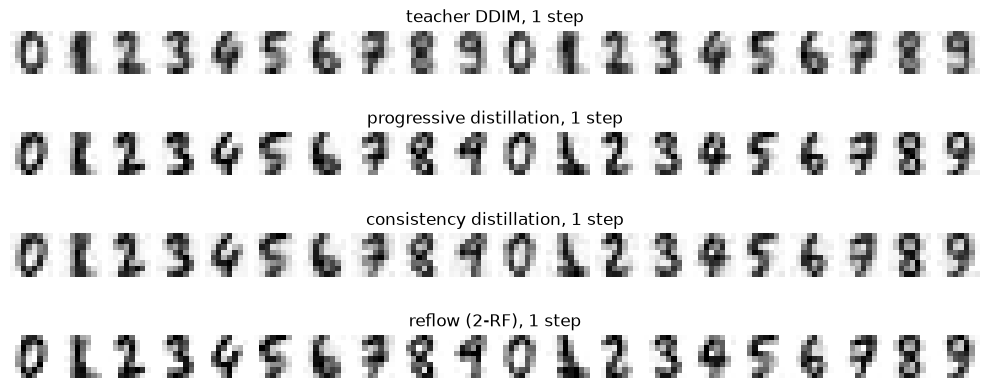

In [6]:
res = pd.DataFrame(results)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for m, g in res.groupby("method", sort=False):
    ax.loglog(g.nfe, g.fd, "o-", label=m)
ax.axhline(real["fd"], ls="--", c="k", lw=1, label="real-data floor")
ax.set_xlabel("network evaluations per sample (NFE)"); ax.set_ylabel("FD (lower is better)"); ax.legend(fontsize=8)
ax.set_title("Few-step generation"); fig.tight_layout(); plt.show()
display(res.pivot_table(index="method", columns="nfe", values="fd", sort=False).round(2))
print(f"training cost: progressive {t_pd:.0f}s | consistency {t_cd:.0f}s | rectified flow {t_rf1:.0f}s | reflow (incl. pair generation) {t_rf2:.0f}s")
fig, axes = plt.subplots(4, 1, figsize=(10, 4.4))
set_seed(0); images.show_grid(dfx.sample_grid(teacher, torch.arange(10).repeat(2), 1), nrow=20, ax=axes[0], title="teacher DDIM, 1 step")
set_seed(0); images.show_grid(dfx.sample_grid(students[1], torch.arange(10).repeat(2), 1), nrow=20, ax=axes[1], title="progressive distillation, 1 step")
set_seed(0); images.show_grid(dfx.sample_consistency(cm, torch.arange(10).repeat(2), 1), nrow=20, ax=axes[2], title="consistency distillation, 1 step")
set_seed(0); images.show_grid(dfx.sample_flow(rf2, torch.arange(10).repeat(2), 1), nrow=20, ax=axes[3], title="reflow (2-RF), 1 step")
fig.tight_layout(); plt.show()

**Reading the comparison.** The table is the result. What to look for:

* **At 1-2 steps every distilled model beats its teacher by a wide margin**, which is the point of distillation.
* **At 4-8 steps the teacher is already good**, and a distilled student can be *worse* than simply running the teacher with fewer DDIM steps. Progressive distillation accumulates a little error in every halving round. Distillation pays off only below the step count where the teacher's own ODE solver breaks down.
* **Reflow trades many-step quality for one-step quality.** The 2-RF model is straighter (lower straightness score) and by far the best 1-step generator here, but at 20 steps it is worse than the flow it was distilled from. Its training targets were the 1-RF model's own 50-step samples, imperfections included.
* **Plain flow matching** is a strong sampler in its own right at moderate step counts. Notebook 09 builds on that.

## 6. Does alignment survive distillation?

Post-training happens in stages. If we align a model first (notebook 07) and distil it afterwards, does the
student keep the alignment? We distil notebook 07's Diffusion-DPO model (bolder digits) from 64 to 4 steps, and
compare the ink reward.

In [7]:
path = os.path.join(CKPT_DIR, "diffusion_dpo.pt")
aligned = dfx.MLPDenoiser()
if os.path.exists(path):
    aligned.load_state_dict(torch.load(path, weights_only=True))
else:                                                   # re-create notebook 07's Diffusion-DPO model (same settings)
    print("checkpoints/diffusion_dpo.pt not found: re-running notebook 07's Diffusion-DPO ...")
    set_seed(1); py = torch.randint(0, 10, (4000,))
    a, b = dfx.sample_ddim(teacher, py, steps=20), dfx.sample_ddim(teacher, py, steps=20)
    w = (dfx.ink(a) > dfx.ink(b))[:, None]
    aligned, _ = dfx.diffusion_dpo(copy.deepcopy(teacher), teacher, torch.where(w, a, b), torch.where(w, b, a), py, iters=800, beta=5000, lr=1e-4, log_every=0)
aligned.eval()
al_students = dfx.progressive_distillation(aligned, Xtr, ytr, start=64, end=4, iters_per_round=600, log=False)
rows = {}
for name, m, N in [("base teacher, 64 steps", teacher, 64), ("aligned teacher, 64 steps", aligned, 64),
                   ("aligned teacher, 4 DDIM steps", aligned, 4), ("distilled aligned student, 4 steps", al_students[4], 4)]:
    set_seed(0); s = dfx.sample_grid(m, yte, N)
    rows[name] = dict(ink=dfx.ink(s).mean().item(), fd_to_data=metrics._frechet(sc.f_te, judge.features(s).numpy()),
                      judge_acc=(judge(s).argmax(1) == yte).float().mean().item())
display(pd.DataFrame(rows).T.round(3))

,ink,fd_to_data,judge_acc
"base teacher, 64 steps",0.307,5.978,0.989
"aligned teacher, 64 steps",0.358,12.754,0.989
"aligned teacher, 4 DDIM steps",0.363,23.018,0.997
"distilled aligned student, 4 steps",0.357,21.030,0.983


Distillation targets come only from the teacher's sampler, so whatever the teacher was aligned to is what the
student learns. Compare the ink of the aligned teacher with that of its distilled 4-step student. The data
used to construct the noisy inputs $x_t$ was the *original* training set, yet the student follows the aligned teacher.
That is why pipelines typically align first and distil last, and why guidance is usually distilled into the student
as well: [Meng et al., 2022](https://arxiv.org/abs/2210.03142) showed how to fold classifier-free guidance into a single model (Challenge Problem 1).

**What remains open.** Every model so far, teacher and students alike, is an MLP that treats the image as one flat vector of 64
numbers and sees its condition only as a label embedding added to its features. Such a model does not scale to
real images or to rich conditioning like text. Notebook 09 replaces it with a **transformer** over image patches.

## 7. Scorecard

In [8]:
best = res.loc[res.groupby("method", sort=False).fd.idxmin()]
one = res[res.nfe == 1]
rows = [dict(model=f"{r.method}, {r.nfe} steps", family="image", fd=r.fd, precision=r.precision, coverage=r.coverage, judge_acc=r.judge_acc, nfe=r.nfe)
        for r in pd.concat([one, best]).drop_duplicates().itertuples()]
metrics.append_rows(rows, "08_distillation")
display(metrics.load_scorecard().query("notebook == '08_distillation'")[["model", "fd", "precision", "coverage", "nfe"]].round(3))
torch.save(rf1.state_dict(), os.path.join(CKPT_DIR, "flow_mlp.pt"))       # notebook 09 compares against it

,model,fd,precision,coverage,nfe
38,"teacher (DDIM), 1 steps",90.883,0.393,0.050,1.0
39,"progressive distillation, 1 steps",24.576,0.922,0.791,1.0
40,"consistency distillation, 1 steps",57.531,0.708,0.460,1.0
41,"rectified flow (1-RF), 1 steps",75.671,0.515,0.106,1.0
42,"reflow (2-RF), 1 steps",19.064,0.916,0.891,1.0
43,"teacher (DDIM), 64 steps",5.978,0.981,0.955,64.0
44,"progressive distillation, 8 steps",11.940,0.975,0.916,8.0
45,"consistency distillation, 4 steps",21.442,0.939,0.819,4.0
46,"rectified flow (1-RF), 20 steps",5.103,0.981,0.964,20.0
47,"reflow (2-RF), 20 steps",7.724,0.978,0.953,20.0


## Challenge Problem 1: Guided distillation

Classifier-free guidance doubles the cost of every step (notebook 06). [Meng et al., 2022](https://arxiv.org/abs/2210.03142) distil the guided teacher's output into a single
student network. Train a copy of the teacher for 1,500 steps to regress the *guided* prediction $(1+w)\,v(x_t, c) - w\,v(x_t, \varnothing)$ with $w = 1$,
at random $t$ and training images. Then compare FD and NFE for (a) the teacher with guidance and (b) the student without guidance, both with 16 DDIM steps.

In [9]:
# Start your code here

### Challenge Problem 1 Solution

In [10]:
import torch.nn.functional as F
set_seed(0)
student_g = copy.deepcopy(teacher).train().requires_grad_(True)
opt = torch.optim.Adam(student_g.parameters(), 1e-4)
for it in range(1500):
    idx = torch.randint(0, len(Xtr), (256,)); x0, c = Xtr[idx], ytr[idx]
    t = torch.randint(0, dfx.T, (256,)); xt = dfx.q_sample(x0, t, torch.randn_like(x0))
    with torch.no_grad():
        target = dfx.guided(teacher, xt, t, c, 1.0)
    loss = F.mse_loss(student_g(xt, t, c), target)
    opt.zero_grad(); loss.backward(); opt.step()
student_g.eval()
set_seed(0); a = sc.evaluate(dfx.sample_ddim(teacher, yte, steps=16, w=1.0), "teacher + CFG w=1, 16 steps", labels=yte, nfe=32)
set_seed(0); b = sc.evaluate(dfx.sample_ddim(student_g, yte, steps=16, w=0.0), "guidance-distilled student, 16 steps", labels=yte, nfe=16)
print(pd.DataFrame([a, b]).set_index("model")[["fd", "precision", "coverage", "nfe"]].round(3))

                                         fd  precision  coverage  nfe
model                                                                
teacher + CFG w=1, 16 steps           3.930      0.989     0.944   32
guidance-distilled student, 16 steps  3.956      0.992     0.947   16


## Challenge Problem 2: Wall-clock, not just NFE

NFE is a proxy for cost. Time the generation of 2,000 samples for: the teacher with 64 DDIM steps, the 1-step progressive student, the 1-step consistency
model and the 1-step 2-RF model. Are the speed-ups close to the NFE ratios? What overheads would change this for a large image model?

In [11]:
# Start your code here

### Challenge Problem 2 Solution

In [12]:
lab = torch.randint(0, 10, (2000,))
for name, fn in [("teacher, 64 steps", lambda: dfx.sample_grid(teacher, lab, 64)),
                 ("progressive, 1 step", lambda: dfx.sample_grid(students[1], lab, 1)),
                 ("consistency, 1 step", lambda: dfx.sample_consistency(cm, lab, 1)),
                 ("2-RF, 1 step", lambda: dfx.sample_flow(rf2, lab, 1))]:
    t0 = time.time(); fn(); print(f"{name:22s} {1000 * (time.time() - t0):7.1f} ms")
# For our tiny MLP, fixed Python overheads matter, so speed-ups are below the NFE ratio. For large latent models, each
# network evaluation dominates, but the VAE decoder and text encoder add a fixed cost that distillation does not remove.

teacher, 64 steps       1041.7 ms
progressive, 1 step       17.4 ms
consistency, 1 step       17.4 ms
2-RF, 1 step              16.5 ms


## Final summary

* Few-step sampling fails because the teacher's ODE trajectories curve and its early $\hat x_0$ estimates are blurry averages.
* **Progressive distillation** halves the step count each round, **consistency distillation** learns a direct map to the trajectory's end, and **reflow** straightens the trajectories so Euler steps are exact. All three turn a model that is useless at 1 step into a usable 1-step generator.
* Distillation is not free: below the teacher's own breaking point it helps, above it a student can be worse than simply running the teacher.
* A distilled student inherits whatever the teacher was aligned to, so pipelines align first and distil last.

## References

* Tim Salimans, Jonathan Ho (2022). **Progressive Distillation for Fast Sampling of Diffusion Models**. arXiv:2202.00512. [arxiv.org/abs/2202.00512](https://arxiv.org/abs/2202.00512)
* Yang Song, Prafulla Dhariwal, Mark Chen et al. (2023). **Consistency Models**. arXiv:2303.01469. [arxiv.org/abs/2303.01469](https://arxiv.org/abs/2303.01469)
* Yang Song, Prafulla Dhariwal (2023). **Improved Techniques for Training Consistency Models**. arXiv:2310.14189. [arxiv.org/abs/2310.14189](https://arxiv.org/abs/2310.14189)
* Xingchao Liu, Chengyue Gong, Qiang Liu (2022). **Flow Straight and Fast: Learning to Generate and Transfer Data with Rectified Flow**. arXiv:2209.03003. [arxiv.org/abs/2209.03003](https://arxiv.org/abs/2209.03003)
* Yaron Lipman, Ricky T. Q. Chen, Heli Ben-Hamu et al. (2022). **Flow Matching for Generative Modeling**. arXiv:2210.02747. [arxiv.org/abs/2210.02747](https://arxiv.org/abs/2210.02747)
* Simian Luo, Yiqin Tan, Longbo Huang et al. (2023). **Latent Consistency Models: Synthesizing High-Resolution Images with Few-Step Inference**. arXiv:2310.04378. [arxiv.org/abs/2310.04378](https://arxiv.org/abs/2310.04378)
* Axel Sauer, Dominik Lorenz, Andreas Blattmann et al. (2023). **Adversarial Diffusion Distillation**. arXiv:2311.17042. [arxiv.org/abs/2311.17042](https://arxiv.org/abs/2311.17042)
* Tianwei Yin, Michaël Gharbi, Richard Zhang et al. (2023). **One-step Diffusion with Distribution Matching Distillation**. arXiv:2311.18828. [arxiv.org/abs/2311.18828](https://arxiv.org/abs/2311.18828)
* Chenlin Meng, Robin Rombach, Ruiqi Gao et al. (2022). **On Distillation of Guided Diffusion Models**. arXiv:2210.03142. [arxiv.org/abs/2210.03142](https://arxiv.org/abs/2210.03142)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).